# Zero-noise extrapolation for mean cost

This experiment asks whether a simple zero-noise extrapolation (ZNE) improves the **mean cost** for one fixed compiled QAOA circuit. It does not try to correct bitstrings or estimate optimum frequency.

We keep the reads, trained angles, physical layout, routing choice and compiled circuit fixed. Only the number of native two-qubit gates changes. The experiment uses FakeManilaV2; trying another backend is deferred.

## 1. Load the shared problem

The setup notebook holds the pilot reads, angles, scoring rule and backend used by the other hardware experiments. These angles are fixed; this test does not train them again.

In [1]:
from pathlib import Path
setup_path = Path('hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('hardware/hardware_setup.ipynb')
if not setup_path.exists():
    setup_path = Path('experiments/hardware/hardware_setup.ipynb')
%run $setup_path

5 SNPs, 9 active interactions, backend: fake_manila
Exact minimum: 1
The reversed SNP order keeps the same ideal output distribution.


## 2. Compile one baseline circuit

Use the original SNP order, physical qubits `0...n-1`, SABRE routing and one fixed transpiler seed. Holding this compiled circuit fixed keeps the comparison focused on noise scaling, not compiler variation.

In [2]:
physical = list(range(n))
compile_seed = 0
pass_manager = generate_preset_pass_manager(
    backend=backend,
    optimization_level=2,
    initial_layout=physical,
    routing_method='sabre',
    seed_transpiler=compile_seed,
)
compiled = pass_manager.run(make_circuit())

if compiled.num_qubits > 16:
    raise ValueError('This Aer noise simulation is limited to 16 physical qubits.')

compiled_ideal = logical_probabilities(compiled)
assert ideal is None or np.allclose(compiled_ideal, ideal)
ideal_mean_cost = sum(
    probability * cost([(state >> bit) & 1 for bit in range(n)])
    for state, probability in enumerate(compiled_ideal)
)
print(f'Backend: {backend.name}; compiled with seed {compile_seed}')
print(f'Ideal mean cost: {ideal_mean_cost:.3f}')

Backend: fake_manila; compiled with seed 0
Ideal mean cost: 7.798


## 3. Fold the native two-qubit gates

ZNE runs equivalent circuits with more noise, estimates the same quantity at each noise level, then extrapolates back to zero. Here, folding replaces each native two-qubit gate `U` by `U U† U` at factor 3. This keeps the ideal operation unchanged while adding two noisy gate applications. We fold the compiled gates locally, after routing, so the layout and gate sequence stay fixed.

This follows [IBM's gate-folding guide](https://quantum.cloud.ibm.com/docs/en/addons/qiskit-mitigation/guides/gate-folding-with-custom-extrapolation) and the digital folding method described by [Giurgica-Tiron et al.](https://arxiv.org/abs/2005.10921). ZNE for expectation values was introduced by [Temme, Bravyi and Gambetta](https://doi.org/10.1103/PhysRevLett.119.180509).

In [3]:
def fold_two_qubit_gates(circuit, factor):
    if factor < 1 or factor % 2 == 0:
        raise ValueError('Use a positive odd noise factor, such as 1 or 3.')

    folded = circuit.copy_empty_like()
    for instruction in circuit.data:
        gate = instruction.operation
        if gate.num_qubits == 2 and gate.name != 'barrier':
            for _ in range((factor - 1) // 2):
                folded.append(gate, instruction.qubits, instruction.clbits)
                folded.append(gate.inverse(), instruction.qubits, instruction.clbits)
        folded.append(gate, instruction.qubits, instruction.clbits)
    return folded

factors = [1, 3]
folded = {factor: fold_two_qubit_gates(compiled, factor) for factor in factors}

for factor, circuit in folded.items():
    assert np.allclose(logical_probabilities(circuit), compiled_ideal)

resource_table = pd.DataFrame([
    {'noise factor': factor, **resources(circuit)}
    for factor, circuit in folded.items()
])
display(resource_table)
print('The folded circuits have the same ideal output probabilities as the baseline.')

,noise factor,2q gates,2q depth,depth
0,1,28,23,57
1,3,84,69,103


The folded circuits have the same ideal output probabilities as the baseline.


## 4. Run a fair shot-budget comparison

The raw baseline uses all `shots` for one noisy estimate. ZNE divides that same total evenly between factors 1 and 3, then uses a straight line through the two mean-cost estimates to extrapolate to factor 0. Each repeat has the same total number of shots in both methods.

A two-point line is a small pilot: it cannot reveal whether the noise response is curved. Factor 5 would increase this circuit from 28 to 140 two-qubit gates and divide the fixed shot budget among three estimates, so it is left out here. Folding scales two-qubit gate exposure, but leaves one-qubit and readout noise unchanged; the noise factor is therefore approximate.

In [4]:
if shots % len(factors):
    raise ValueError('Choose a total shot budget divisible by the number of noise factors.')

shots_per_factor = shots // len(factors)
repeats = noise_repeats
simulator = AerSimulator.from_backend(backend, max_parallel_threads=1)
records = []

for repeat in range(repeats):
    raw_counts = simulator.run(
        compiled,
        shots=shots,
        seed_simulator=7000 + repeat,
    ).result().get_counts()
    records.append({
        'repeat': repeat,
        'method': 'Raw baseline',
        'noise factor': 1,
        'shots': shots,
        'mean cost': score(raw_counts)['mean cost'],
    })

    factor_costs = {}
    for factor in factors:
        counts = simulator.run(
            folded[factor],
            shots=shots_per_factor,
            seed_simulator=8000 + 100 * factor + repeat,
        ).result().get_counts()
        mean_cost = score(counts)['mean cost']
        factor_costs[factor] = mean_cost
        records.append({
            'repeat': repeat,
            'method': 'ZNE data',
            'noise factor': factor,
            'shots': shots_per_factor,
            'mean cost': mean_cost,
        })

    zne_cost = (3 * factor_costs[1] - factor_costs[3]) / 2
    records.append({
        'repeat': repeat,
        'method': 'ZNE estimate',
        'noise factor': 0,
        'shots': shots,
        'mean cost': zne_cost,
    })

results = pd.DataFrame(records)
summary = (results[results.method.isin(['Raw baseline', 'ZNE estimate'])]
           .groupby('method')['mean cost']
           .agg(['mean', 'std']))
summary['standard error'] = summary['std'] / np.sqrt(repeats)
comparison = results[results.method.isin(['Raw baseline', 'ZNE estimate'])]
display(comparison.pivot(index='repeat', columns='method', values='mean cost'))
display(summary)
print(f'Per repeat: raw = {shots} shots; ZNE = {shots_per_factor} + {shots_per_factor} = {shots} shots.')

method,Raw baseline,ZNE estimate
repeat,,
0,9.650879,8.997559
1,9.726074,9.215332
2,9.516602,9.224609


,mean,std,standard error
method,,,
Raw baseline,9.631185,0.106116,0.061266
ZNE estimate,9.145833,0.128493,0.074186


Per repeat: raw = 2048 shots; ZNE = 1024 + 1024 = 2048 shots.


## 5. Read the result

The first plot shows the mean cost at each ZNE factor, including the straight-line intercept at zero. Error bars show the standard deviation across independent repeats. The second plot compares the raw and extrapolated estimates with the ideal reference. A lower cost is better.

The ZNE estimate is only an extrapolated **mean cost**. It does not produce a corrected sample distribution or corrected optimum frequency. With only a few repeats, the spread is a rough indication of sampling variability, not a strong statistical conclusion.

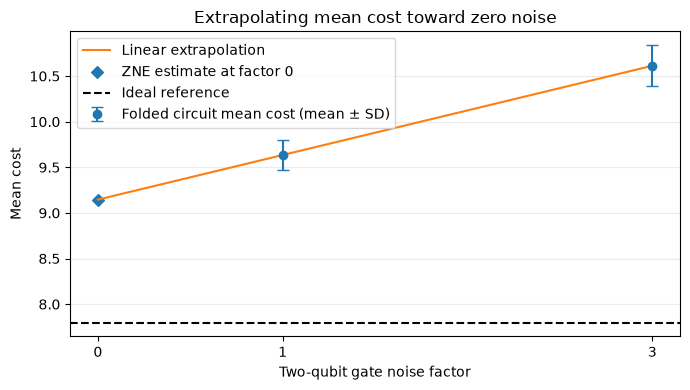

In [5]:
zne_data = results[results.method == 'ZNE data']
factor_summary = zne_data.groupby('noise factor')['mean cost'].agg(['mean', 'std'])

x = np.array(factor_summary.index, dtype=float)
y = factor_summary['mean'].to_numpy()
line = np.polyfit(x, y, 1)
fit_x = np.linspace(0, 3, 60)

fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(x, y, yerr=factor_summary['std'], fmt='o', capsize=4,
            label='Folded circuit mean cost (mean ± SD)')
ax.plot(fit_x, np.polyval(line, fit_x), label='Linear extrapolation')
ax.scatter([0], [np.polyval(line, 0)], marker='D', label='ZNE estimate at factor 0')
ax.axhline(ideal_mean_cost, color='black', linestyle='--', label='Ideal reference')
ax.set(xticks=[0, 1, 3], xlabel='Two-qubit gate noise factor', ylabel='Mean cost',
       title='Extrapolating mean cost toward zero noise')
ax.grid(axis='y', alpha=.25)
ax.legend(loc='best')
fig.tight_layout()
plt.show()

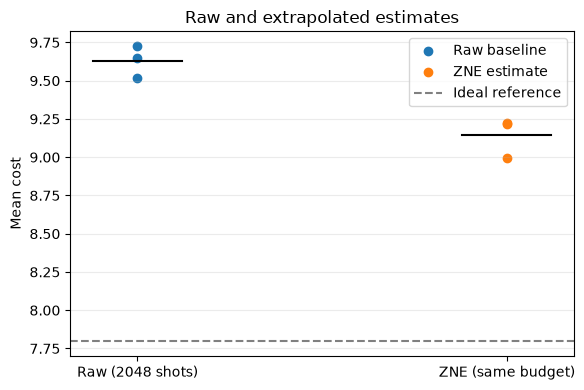

In [6]:
comparison = results[results.method.isin(['Raw baseline', 'ZNE estimate'])]
fig, ax = plt.subplots(figsize=(6, 4))
for position, method in enumerate(['Raw baseline', 'ZNE estimate']):
    values = comparison.loc[comparison.method == method, 'mean cost'].to_numpy()
    ax.scatter(np.full(len(values), position), values, label=method)
    ax.plot([position - .12, position + .12], [values.mean(), values.mean()], color='black')
ax.axhline(ideal_mean_cost, color='gray', linestyle='--', label='Ideal reference')
ax.set(xticks=[0, 1], xticklabels=['Raw (2048 shots)', 'ZNE (same budget)'],
       ylabel='Mean cost', title='Raw and extrapolated estimates')
ax.grid(axis='y', alpha=.25)
ax.legend()
fig.tight_layout()
plt.show()

## What did I find?

In this saved FakeManilaV2 run, the equal-budget raw estimate was **9.63**, and the ZNE estimate was **9.15**. The ideal mean cost was **7.80**, so ZNE moved the estimate closer, but it did not remove the gap. There were only three repeats and two noise factors; treat this as a promising pilot, not evidence that ZNE will help on other inputs or backends.